# myPolar — Model Comparison
Traditional ML baseline vs. Bi-LSTM, Transformer (from scratch) and fine-tuned XLM-RoBERTa on the three tasks.

This notebook only reads result files; it does not train anything.

| File | Produced by |
|---|---|
| `results/baseline_traditional_ml.csv` | best model per task, copied from `../baseline_traditional_ml/baseline_traditional_ml.ipynb` |
| `results/bilstm.csv`, `results/transformer.csv`, `results/xlmr.csv` | `polar_models.py` (training logs in `logs/`) |
| `results/contributor_holdout.csv` | `contributor_holdout.py` + `polar_models.py --splits splits_contributor` |

All models use the same train / val / test splits. The epoch (or C for the baseline) is chosen on validation macro F1 and the test score is read at that point. Bi-LSTM and Transformer are averaged over 3 seeds; XLM-R is a single run.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

NAMES = {"bilstm": "Bi-LSTM (syllable)", "transformer": "Transformer (syllable)", "xlmr": "XLM-R base (fine-tuned)"}
ORDER = ["TF-IDF + linear (baseline)", *NAMES.values()]

base = pd.read_csv("results/baseline_traditional_ml.csv").assign(seed=0)
base["config"], base["model"] = base["model"], ORDER[0]
neural = pd.concat([pd.read_csv(f"results/{m}.csv") for m in NAMES], ignore_index=True)
neural["model"] = neural["model"].map(NAMES)
runs = pd.concat([base, neural], ignore_index=True)
runs.groupby(["task", "model"]).size().unstack("task").loc[ORDER].rename_axis("runs per task", axis=1)

runs per task,task1,task2,task3
model,,,
TF-IDF + linear (baseline),1,1,1
Bi-LSTM (syllable),3,3,3
Transformer (syllable),3,3,3
XLM-R base (fine-tuned),1,1,1


## Macro F1 on the test set

In [2]:
agg = runs.groupby(["model", "task"]).agg(val=("val_macro_f1", "mean"), test=("test_macro_f1", "mean"),
                                         std=("test_macro_f1", "std"), n=("seed", "size")).reset_index()
agg["cell"] = agg.apply(lambda r: f"{r.test:.3f}" + (f" ± {r['std']:.3f}" if r.n > 1 else ""), axis=1)
table = agg.pivot(index="model", columns="task", values="cell").loc[ORDER]
table.columns = ["Task 1 polarization", "Task 2 type", "Task 3 manifestation"]
table

,Task 1 polarization,Task 2 type,Task 3 manifestation
model,,,
TF-IDF + linear (baseline),0.790,0.572,0.509
Bi-LSTM (syllable),0.759 ± 0.001,0.522 ± 0.005,0.482 ± 0.013
Transformer (syllable),0.760 ± 0.012,0.473 ± 0.005,0.447 ± 0.003
XLM-R base (fine-tuned),0.770,0.560,0.481


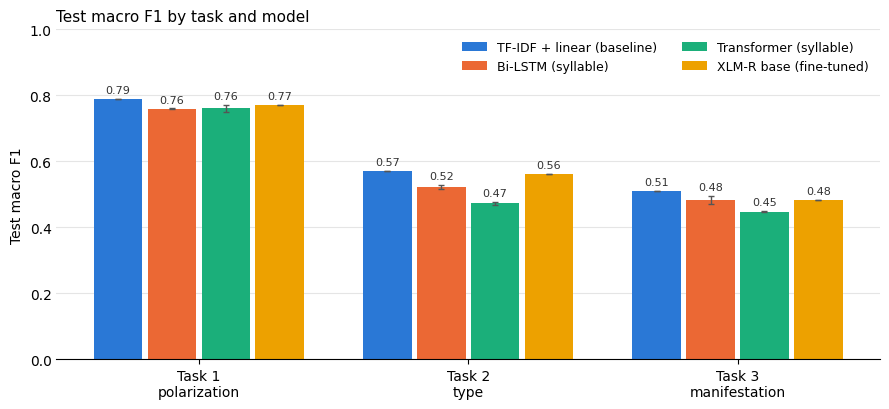

In [3]:
test = agg.pivot(index="model", columns="task", values="test").loc[ORDER]
err = agg.pivot(index="model", columns="task", values="std").loc[ORDER].fillna(0)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, ax = plt.subplots(figsize=(9, 4.2))
w = 0.2
for i, (model, c) in enumerate(zip(ORDER, COLORS)):
    xs = [t + (i - 1.5) * w for t in range(3)]
    bars = ax.bar(xs, test.loc[model], w - 0.02, color=c, label=model, yerr=err.loc[model], ecolor="#555", capsize=2, error_kw={"lw": 1})
    for x, v, e in zip(xs, test.loc[model], err.loc[model]):
        ax.text(x, v + e + 0.012, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color="#333")
ax.set_xticks(range(3), ["Task 1\npolarization", "Task 2\ntype", "Task 3\nmanifestation"])
ax.set_ylabel("Test macro F1"); ax.set_ylim(0, 1)
ax.set_title("Test macro F1 by task and model", loc="left", fontsize=11)
ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=2, loc="upper right", fontsize=9)
fig.tight_layout(); fig.savefig("results/model_comparison.png", dpi=160); plt.show()

## Validation vs. test, and the selected epoch

In [4]:
agg2 = runs.groupby(["task", "model"]).agg(val_macro_f1=("val_macro_f1", "mean"), test_macro_f1=("test_macro_f1", "mean"),
                                           mean_best_epoch=("best_epoch", "mean")).round(4)
agg2.reindex(ORDER, level="model")

val_macro_f1  test_macro_f1  mean_best_epoch
task  model                                                                   
task1 TF-IDF + linear (baseline)        0.7964         0.7899              NaN
      Bi-LSTM (syllable)                0.7752         0.7591          10.0000
      Transformer (syllable)            0.7655         0.7603          12.3333
      XLM-R base (fine-tuned)           0.8113         0.7700           4.0000
task2 TF-IDF + linear (baseline)        0.5640         0.5716              NaN
      Bi-LSTM (syllable)                0.5422         0.5221          12.6667
      Transformer (syllable)            0.4896         0.4730          26.0000
      XLM-R base (fine-tuned)           0.5663         0.5600           3.0000
task3 TF-IDF + linear (baseline)        0.5242         0.5092              NaN
      Bi-LSTM (syllable)                0.4920         0.4824          18.3333
      Transformer (syllable)            0.4523         0.4472          12.0000
      XLM-R base (fine-tuned)           0.4943         0.4813           4.0000

## Per-label test F1 (Tasks 2 and 3)
Mean over seeds.

In [5]:
def per_label(task):
    r = runs[runs.task == task]
    rows = pd.DataFrame([json.loads(s) for s in r.per_label_test_f1], index=r.model.values)
    return rows.groupby(level=0).mean().loc[ORDER].T.round(3)

per_label("task2")

,TF-IDF + linear (baseline),Bi-LSTM (syllable),Transformer (syllable),XLM-R base (fine-tuned)
political,0.693,0.678,0.631,0.679
racial/ethnic,0.583,0.525,0.485,0.538
religious,0.494,0.420,0.342,0.486
gender/sexual,0.603,0.533,0.465,0.641
other,0.486,0.455,0.442,0.455


In [6]:
per_label("task3")

,TF-IDF + linear (baseline),Bi-LSTM (syllable),Transformer (syllable),XLM-R base (fine-tuned)
stereotype,0.468,0.434,0.386,0.425
vilification,0.646,0.622,0.606,0.666
dehumanization,0.479,0.489,0.429,0.460
extreme_language,0.544,0.530,0.506,0.527
lack_of_empathy,0.468,0.400,0.366,0.388
invalidation,0.450,0.420,0.391,0.422


## Robustness check: unseen contributors (Task 1)
The polarization rate differs strongly between contributors (0 % to 99 %), and the standard splits are random, so each contributor's sentences are on both sides of the split. Here whole contributors are held out: the validation and test contributors never appear in training. One split, one seed — read it as an indication, not a precise estimate.

In [7]:
ho = pd.read_csv("results/contributor_holdout.csv")
ho["model"] = ho["model"].map(lambda m: NAMES.get(m, ORDER[0]))
std_split = test["task1"].rename("random split (test)")
out = ho.set_index("model")[["val_macro_f1", "test_macro_f1"]].rename(columns={"val_macro_f1": "held-out contributors (val)", "test_macro_f1": "held-out contributors (test)"})
out = out.join(std_split).loc[[m for m in ORDER if m in out.index]]
out["drop"] = (out["random split (test)"] - out["held-out contributors (test)"]).round(4)
out.round(4)

,held-out contributors (val),held-out contributors (test),random split (test),drop
model,,,,
TF-IDF + linear (baseline),0.6202,0.6023,0.7899,0.1876
Bi-LSTM (syllable),0.6256,0.6624,0.7591,0.0967
Transformer (syllable),0.6107,0.6290,0.7603,0.1313
XLM-R base (fine-tuned),0.6585,0.6580,0.7700,0.1120
